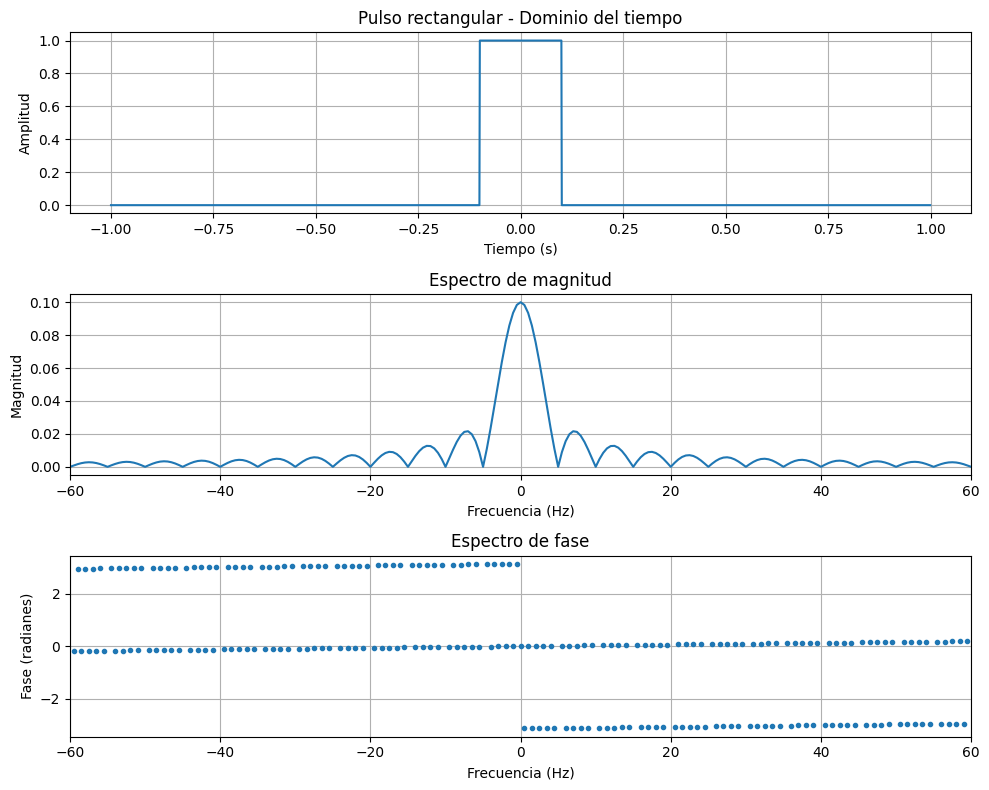

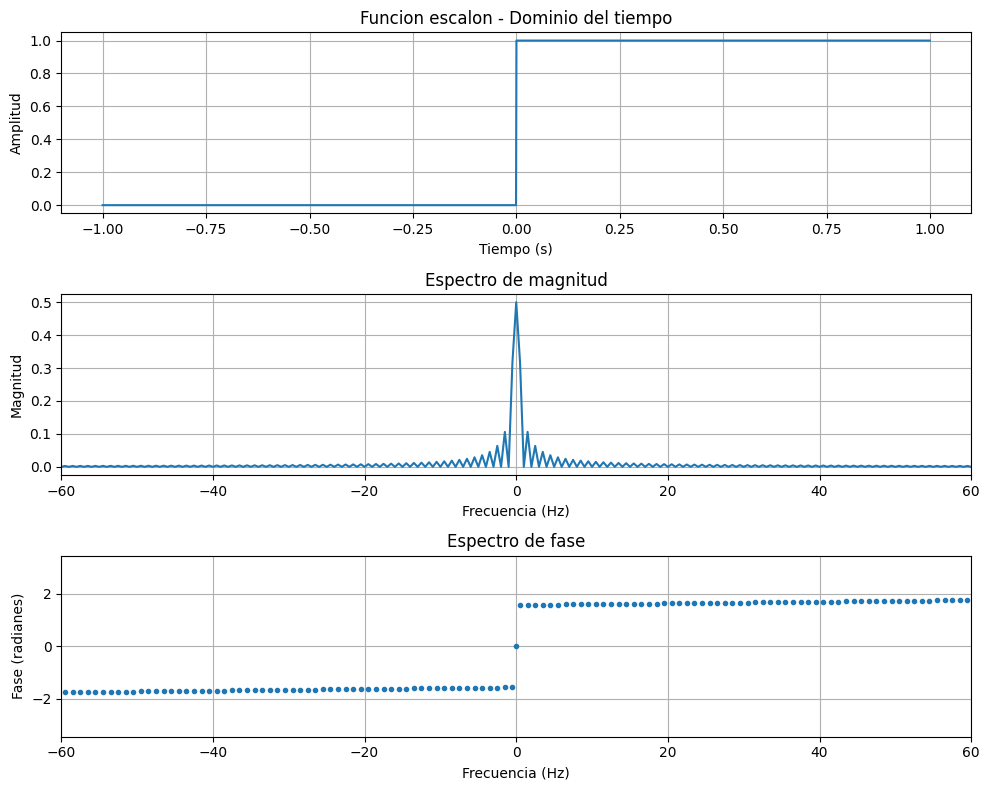

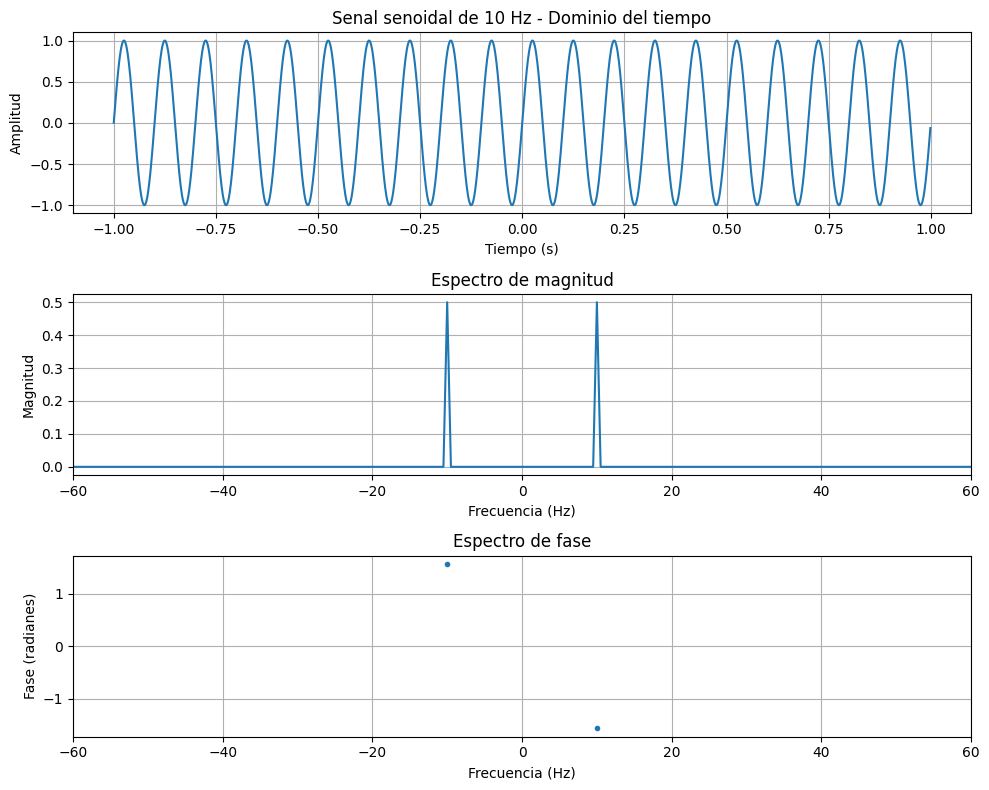

Analisis de las tres senales completado.


In [2]:

# ACTIVIDAD FORMATIVA 2
# Transformada de Fourier - Señales y Sistemas

import numpy as np
import matplotlib.pyplot as plt

# 1. Configuracion
fs = 1000
dt = 1 / fs
t = np.arange(-1, 1, dt)
N = len(t)

# Eje de frecuencias
f = np.fft.fftshift(np.fft.fftfreq(N, d=dt))

# 2. Crear las tres señales solicitadas

# Pulso rectangular
pulso = np.where(np.abs(t) <= 0.1, 1.0, 0.0)

# Funcion escalon
escalon = np.where(t >= 0, 1.0, 0.0)

# Senal senoidal de 10 Hz
f0 = 10
senoidal = np.sin(2 * np.pi * f0 * t)

# 3. Funcion para calcular la FFT
def analizar_senal(x):
    X = np.fft.fftshift(np.fft.fft(x))
    magnitud = np.abs(X) / len(x)
    fase = np.angle(X)
    return magnitud, fase

# 4. Graficar tiempo, magnitud y fase
senales = [
    ("Pulso rectangular", pulso),
    ("Funcion escalon", escalon),
    ("Senal senoidal de 10 Hz", senoidal)
]

for nombre, x in senales:
    magnitud, fase = analizar_senal(x)
    mascara = magnitud > magnitud.max() * 1e-4

    fig, ax = plt.subplots(3, 1, figsize=(10, 8))

    ax[0].plot(t, x)
    ax[0].set_title(nombre + " - Dominio del tiempo")
    ax[0].set_xlabel("Tiempo (s)")
    ax[0].set_ylabel("Amplitud")
    ax[0].grid(True)

    ax[1].plot(f, magnitud)
    ax[1].set_title("Espectro de magnitud")
    ax[1].set_xlabel("Frecuencia (Hz)")
    ax[1].set_ylabel("Magnitud")
    ax[1].set_xlim(-60, 60)
    ax[1].grid(True)

    ax[2].plot(f[mascara], fase[mascara], ".")
    ax[2].set_title("Espectro de fase")
    ax[2].set_xlabel("Frecuencia (Hz)")
    ax[2].set_ylabel("Fase (radianes)")
    ax[2].set_xlim(-60, 60)
    ax[2].grid(True)

    plt.tight_layout()
    plt.show()

print("Analisis de las tres senales completado.")


1. LINEALIDAD
Error: 2.2744037044374025e-13
Se cumple: True

2. DESPLAZAMIENTO TEMPORAL
Se conserva la magnitud: True


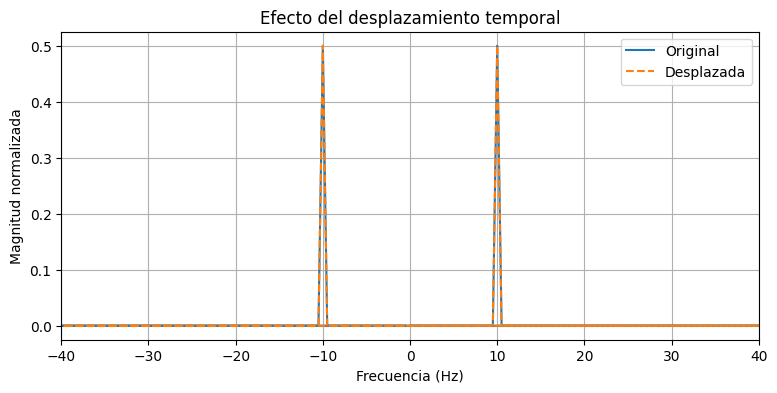

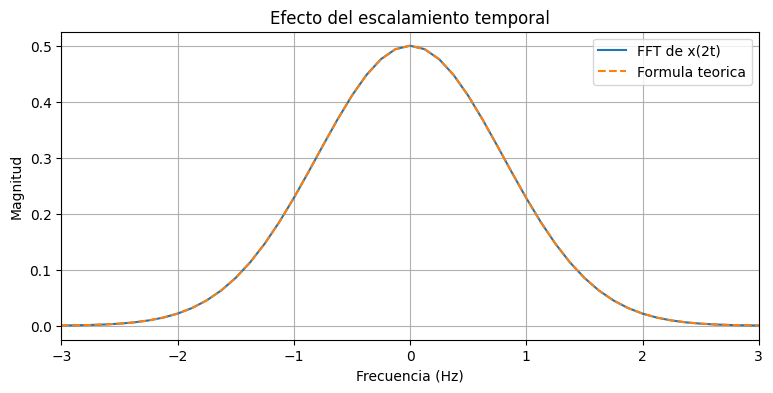


3. ESCALAMIENTO
La compresion temporal ensancha el espectro.


In [3]:

# VERIFICACION DE LAS PROPIEDADES DE FOURIER

# A. LINEALIDAD
x1 = np.sin(2 * np.pi * 10 * t)
x2 = 0.5 * np.cos(2 * np.pi * 20 * t)

a, b = 2, 3

X_combinada = np.fft.fft(a * x1 + b * x2)
X_separadas = a * np.fft.fft(x1) + b * np.fft.fft(x2)

print("1. LINEALIDAD")
print("Error:", np.max(np.abs(X_combinada - X_separadas)))
print("Se cumple:", np.allclose(X_combinada, X_separadas))

# B. DESPLAZAMIENTO TEMPORAL
desplazamiento = 25
x_movida = np.roll(x1, desplazamiento)

X_original = np.fft.fft(x1)
X_movida = np.fft.fft(x_movida)

print("\n2. DESPLAZAMIENTO TEMPORAL")
print("Se conserva la magnitud:",
      np.allclose(np.abs(X_original), np.abs(X_movida)))

f_prueba = np.fft.fftfreq(N, d=dt)

plt.figure(figsize=(9, 4))
plt.plot(f_prueba, np.abs(X_original) / N, label="Original")
plt.plot(f_prueba, np.abs(X_movida) / N, "--", label="Desplazada")
plt.xlim(-40, 40)
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud normalizada")
plt.title("Efecto del desplazamiento temporal")
plt.grid(True)
plt.legend()
plt.show()

# C. ESCALAMIENTO
tg = np.arange(-4, 4, 0.002)
dtg = tg[1] - tg[0]
Ng = len(tg)

# Senal gaussiana y su version comprimida
xg = np.exp(-np.pi * tg**2)
xg2 = np.exp(-np.pi * (2 * tg)**2)

fg = np.fft.fftshift(np.fft.fftfreq(Ng, d=dtg))

Xg2 = np.fft.fftshift(np.fft.fft(xg2)) * dtg

# Transformada teorica de x(2t)
X_teorica = 0.5 * np.exp(-np.pi * (fg / 2)**2)

plt.figure(figsize=(9, 4))
plt.plot(fg, np.abs(Xg2), label="FFT de x(2t)")
plt.plot(fg, X_teorica, "--", label="Formula teorica")
plt.xlim(-3, 3)
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Magnitud")
plt.title("Efecto del escalamiento temporal")
plt.grid(True)
plt.legend()
plt.show()

print("\n3. ESCALAMIENTO")
print("La compresion temporal ensancha el espectro.")
